<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/empathy_agent_moderation_simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# [CELL 1 - Environment Setup & Synthetic Participant Dataset Generator]
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"HCI Empathy Interaction Simulation Engine Initialized on: {device}")

class OlderAdultEmpathyDataset:
    """
    Simulates older adult participant profiles (N=240) with:
    - Trait Affective Empathy (Standardized 0-1)
    - Trait Cognitive Empathy (Standardized 0-1)
    - Agent Dialogue Condition (0: Baseline, 1: Affective, 2: Cognitive)
    - Target Perceived Empathy Score (0-1) based on Zhang et al. interaction findings
    """
    def __init__(self, num_samples: int = 300):
        self.num_samples = num_samples

    def generate_data(self) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        trait_affective = torch.rand(self.num_samples, 1, device=device)
        trait_cognitive = torch.rand(self.num_samples, 1, device=device)

        # Categorical dialogue condition encoded as one-hot or integer (0: Baseline, 1: Affective, 2: Cognitive)
        condition_idx = torch.randint(0, 3, (self.num_samples, 1), device=device).float()

        # Simulate grounded interaction dynamics from the paper:
        # Affective dialogue interacts with cognitive trait; Cognitive dialogue interacts with affective trait.
        noise = torch.randn(self.num_samples, 1, device=device) * 0.05

        base_score = 0.4 + 0.2 * trait_affective + 0.2 * trait_cognitive
        # Condition effects and moderation bumps
        cond_effect = torch.where(condition_idx == 1, 0.15 + 0.25 * trait_cognitive,
                                  torch.where(condition_idx == 2, 0.18 + 0.28 * trait_affective, 0.0))

        perceived_empathy = torch.clamp(base_score + cond_effect + noise, 0.0, 1.0)

        features = torch.cat([trait_affective, trait_cognitive, condition_idx], dim=1)
        return features, perceived_empathy

dataset_gen = OlderAdultEmpathyDataset(num_samples=300)
X, y = dataset_gen.generate_data()
print(f"Synthetic Older Adult HCI Dataset Loaded:")
print(f"  * Total Simulated Participant Trials: {X.shape[0]}")
print(f"  * Feature Dimensions (Trait Affective, Trait Cognitive, Dialogue Condition): {X.shape[1]}")

HCI Empathy Interaction Simulation Engine Initialized on: cuda
Synthetic Older Adult HCI Dataset Loaded:
  * Total Simulated Participant Trials: 300
  * Feature Dimensions (Trait Affective, Trait Cognitive, Dialogue Condition): 3


In [2]:
# [CELL 2 - Empathy Interaction Neural Prediction Model & Loss]

class EmpathyInteractionModel(nn.Module):
    """
    Models the nonlinear interaction between agent dialogue strategy
    and older adult trait empathy in healthcare robotic agents.
    """
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, 32),
            nn.LayerNorm(32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
            nn.Sigmoid()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

model = EmpathyInteractionModel().to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-2, weight_decay=1e-4)

print("Empathy Interaction & Moderation Network Initialized.")

Empathy Interaction & Moderation Network Initialized.


In [3]:
# [CELL 3 - Empathy Interaction Training Pipeline]

class EmpathyTrainingPipeline:
    def __init__(self, model: nn.Module, X: torch.Tensor, y: torch.Tensor):
        self.model = model
        self.X = X
        self.y = y
        self.optimizer = optim.Adam(self.model.parameters(), lr=1e-2)
        self.criterion = nn.MSELoss()
        self.loss_history = []

    def train(self, epochs: int = 250):
        self.model.train()
        for epoch in range(epochs):
            self.optimizer.zero_grad()
            preds = self.model(self.X)
            loss = self.criterion(preds, self.y)
            loss.backward()
            self.optimizer.step()
            self.loss_history.append(loss.item())

    def evaluate_mse(self) -> float:
        self.model.eval()
        with torch.no_grad():
            preds = self.model(self.X)
            mse = self.criterion(preds, self.y).item()
        return mse

pipeline = EmpathyTrainingPipeline(model, X, y)
print("Training Empathy Interaction Model on Simulated Older Adult Responses...")
pipeline.train(epochs=250)
final_mse = pipeline.evaluate_mse()
print(f"Training Complete. Interaction Model Final MSE: {final_mse:.5f}")

Training Empathy Interaction Model on Simulated Older Adult Responses...
Training Complete. Interaction Model Final MSE: 0.00151


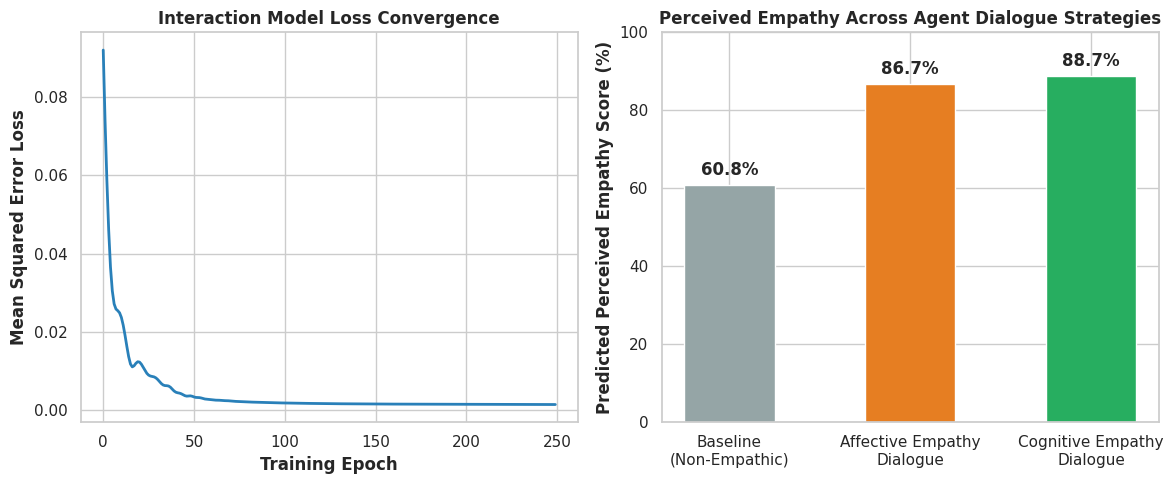

HCI Empathy benchmark visualization saved successfully as empathy_agent_moderation_benchmarks.png.


In [4]:
# [CELL 4 - Multi-Panel Visualization of Empathy Moderation & Convergence]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Training Loss Convergence
ax1.plot(range(len(pipeline.loss_history)), pipeline.loss_history, color='#2980b9', linewidth=2)
ax1.set_title("Interaction Model Loss Convergence", fontweight='bold')
ax1.set_xlabel("Training Epoch", fontweight='bold')
ax1.set_ylabel("Mean Squared Error Loss", fontweight='bold')

# Plot 2: Perceived Empathy by Dialogue Strategy and Trait Moderation
conditions = ['Baseline\n(Non-Empathic)', 'Affective Empathy\nDialogue', 'Cognitive Empathy\nDialogue']
model.eval()
with torch.no_grad():
    # Evaluate mean predicted perceived empathy per condition across simulated cohort
    cond_means = []
    for c_val in [0.0, 1.0, 2.0]:
        subset_X = X.clone()
        subset_X[:, 2] = c_val
        pred_scores = model(subset_X)
        cond_means.append(pred_scores.mean().item() * 100.0)

bars = ax2.bar(conditions, cond_means, color=['#95a5a6', '#e67e22', '#27ae60'], width=0.5)
ax2.set_title("Perceived Empathy Across Agent Dialogue Strategies", fontweight='bold')
ax2.set_ylabel("Predicted Perceived Empathy Score (%)", fontweight='bold')
ax2.set_ylim(0, 100)

for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f"{yval:.1f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("empathy_agent_moderation_benchmarks.png", dpi=300)
plt.show()

print("HCI Empathy benchmark visualization saved successfully as empathy_agent_moderation_benchmarks.png.")